<a href="https://colab.research.google.com/github/FantinelBruna/pcd-unijui/blob/main/atividade/atividadeAula10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45]
}

df = pd.DataFrame(dados)

print(df)

   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38
5  Jun        40     70       45


### Parte 1: Exploração dos dados

In [2]:
print("Primeiras linhas:")
print(df.head())

print("\nDimensões:", df.shape)
print("Quantidade de linhas:", df.shape[0])
print("Quantidade de colunas:", df.shape[1])

print("\nEstatísticas descritivas:")
print(df.describe().round(2))

Primeiras linhas:
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38

Dimensões: (6, 4)
Quantidade de linhas: 6
Quantidade de colunas: 4

Estatísticas descritivas:
       Notebook  Mouse  Teclado
count      6.00   6.00     6.00
mean      28.67  58.00    36.00
std        7.79   8.60     6.36
min       20.00  48.00    28.00
25%       22.75  51.25    31.25
50%       27.50  57.50    36.50
75%       33.75  63.75    39.50
max       40.00  70.00    45.00


### Parte 2: Indicadores

In [3]:
produtos = df[["Notebook", "Mouse", "Teclado"]]

vendas = produtos.to_numpy()

medias = np.mean(vendas, axis=0)
maiores = np.max(vendas, axis=0)
menores = np.min(vendas, axis=0)

indicadores = pd.DataFrame({
    "Produto": produtos.columns,
    "Media": np.round(medias, 2),
    "Maior venda": maiores,
    "Menor venda": menores
})

print(indicadores)

    Produto  Media  Maior venda  Menor venda
0  Notebook  28.67           40           20
1     Mouse  58.00           70           48
2   Teclado  36.00           45           28


### Parte 3: Evolução temporal

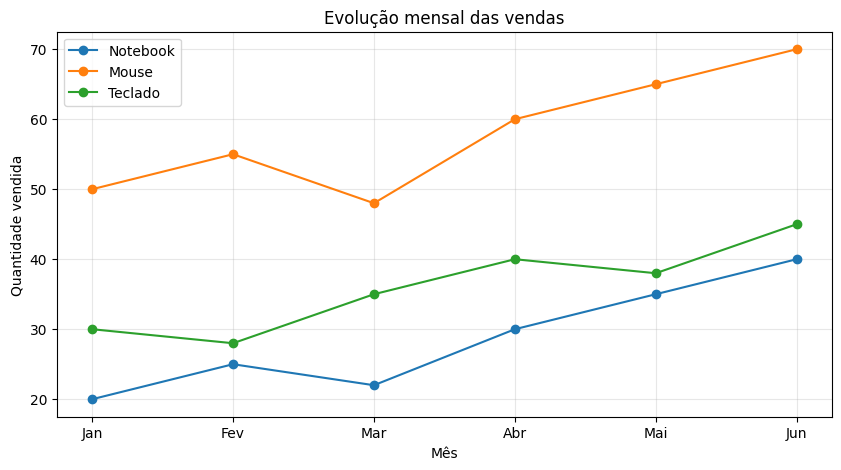

In [4]:
plt.figure(figsize=(10, 5))

plt.plot(df["Mes"], df["Notebook"], marker="o", label="Notebook")
plt.plot(df["Mes"], df["Mouse"], marker="o", label="Mouse")
plt.plot(df["Mes"], df["Teclado"], marker="o", label="Teclado")

plt.title("Evolução mensal das vendas")
plt.xlabel("Mês")
plt.ylabel("Quantidade vendida")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Parte 4: Comparação

Total vendido por produto:
Notebook    172
Mouse       348
Teclado     216
dtype: int64


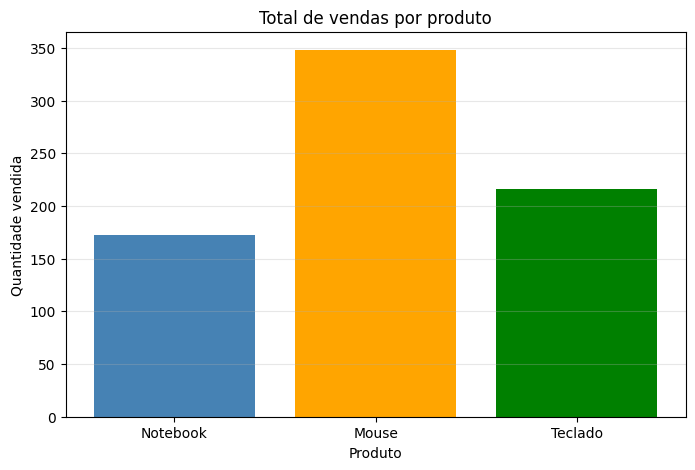

In [5]:
totais = np.sum(vendas, axis=0)

print("Total vendido por produto:")
print(pd.Series(totais, index=produtos.columns))

plt.figure(figsize=(8, 5))

plt.bar(produtos.columns, totais, color=["steelblue", "orange", "green"])

plt.title("Total de vendas por produto")
plt.xlabel("Produto")
plt.ylabel("Quantidade vendida")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Parte 5: Distribuição

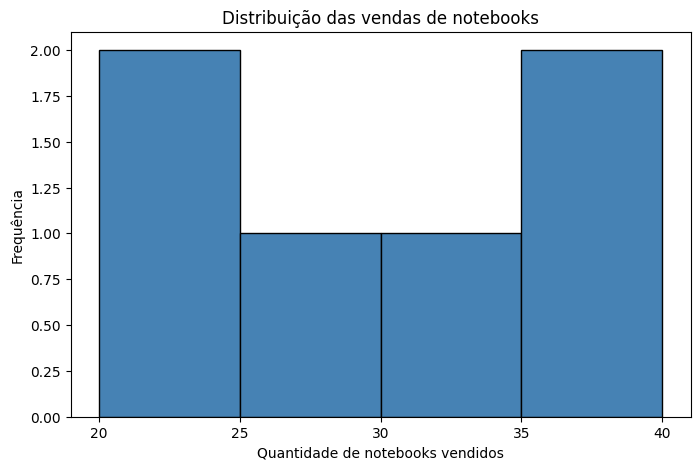

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(df["Notebook"], bins=4, color="steelblue", edgecolor="black")

plt.title("Distribuição das vendas de notebooks")
plt.xlabel("Quantidade de notebooks vendidos")
plt.ylabel("Frequência")
plt.xticks([20, 25, 30, 35, 40])

plt.show()

### Parte 6: Interpretação

In [7]:
indice_maior = np.argmax(totais)

print("Produto mais vendido:", produtos.columns[indice_maior])
print("Quantidade vendida:", totais[indice_maior])

melhores_meses = np.argmax(vendas, axis=0)

resultado = pd.DataFrame({
    "Produto": produtos.columns,
    "Melhor mes": df["Mes"].to_numpy()[melhores_meses],
    "Quantidade": np.max(vendas, axis=0)
})

print("\nMelhor mês de cada produto:")
print(resultado)

Produto mais vendido: Mouse
Quantidade vendida: 348

Melhor mês de cada produto:
    Produto Melhor mes  Quantidade
0  Notebook        Jun          40
1     Mouse        Jun          70
2   Teclado        Jun          45


---
### Desafio: Nova visualização

Média de vendas: 28.67

Meses abaixo da média:
   Mes  Notebook
0  Jan        20
1  Fev        25
2  Mar        22


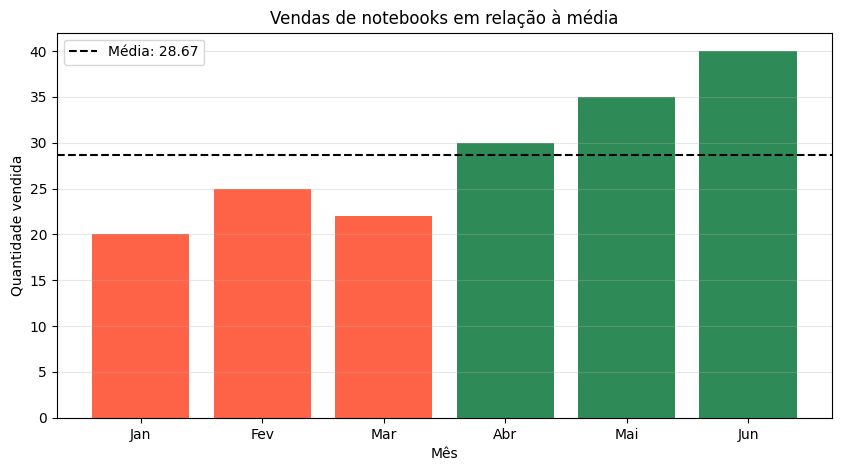

In [8]:
media_notebooks = np.mean(df["Notebook"])

abaixo_media = df[df["Notebook"] < media_notebooks]

print(f"Média de vendas: {media_notebooks:.2f}")

print("\nMeses abaixo da média:")
print(abaixo_media[["Mes", "Notebook"]])

cores = np.where(
    df["Notebook"] < media_notebooks,
    "tomato",
    "seagreen"
)

plt.figure(figsize=(10, 5))

plt.bar(df["Mes"], df["Notebook"], color=cores)

plt.axhline(
    media_notebooks,
    color="black",
    linestyle="--",
    label=f"Média: {media_notebooks:.2f}"
)

plt.title("Vendas de notebooks em relação à média")
plt.xlabel("Mês")
plt.ylabel("Quantidade vendida")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

## Conclusão

Com a análise dos dados de vendas, foi possível identificar o comportamento dos três produtos comercializados durante o primeiro semestre.

O Mouse apresentou o maior volume de vendas, com 348 unidades, seguido pelo Teclado, com 216 unidades, e pelo Notebook, com 172 unidades. Apesar de apresentar o menor volume total, o Notebook demonstrou um crescimento significativo, passando de 20 unidades vendidas em janeiro para 40 em junho, representando um aumento de 100%.

Os gráficos permitiram identificar uma tendência geral de crescimento nas vendas, sendo junho o mês com os melhores resultados para todos os produtos. A análise adicional das vendas de notebooks também demonstrou que os últimos três meses apresentaram resultados superiores à média do período.

A utilização das bibliotecas Pandas, NumPy e Matplotlib facilitou a organização dos dados, a realização dos cálculos estatísticos e a construção de visualizações, permitindo identificar padrões e interpretar os resultados de maneira mais clara e objetiva.